In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/processed/cleaned_deliveries.csv",
    dtype={"ball": str, "match_id": str},
    low_memory=False,
)

# Use the flags we already validated
df["is_batter_dismissal"] = (
    df["is_wicket"] & (df["player_dismissed"] == df["striker"])
).astype(int)

MIN_BALLS_MATCHUP = 20

matchups = df.groupby(["striker", "bowler"]).agg(
    balls_faced=("wides", lambda x: x.isna().sum()),  # non-wide = ball faced
    runs=("runs_off_bat", "sum"),
    dismissals=("is_batter_dismissal", "sum"),
    dots=("is_legal", "sum"),  # placeholder; fixed below
).reset_index()

# Recompute dots properly
dots = df[df["is_legal"] & (df["runs_off_bat"] == 0)] \
    .groupby(["striker", "bowler"]).size().rename("dots").reset_index()
matchups = matchups.drop(columns="dots").merge(dots, on=["striker", "bowler"], how="left")
matchups["dots"] = matchups["dots"].fillna(0).astype(int)

matchups["SR"] = (matchups["runs"] / matchups["balls_faced"] * 100).round(1)
matchups["dot_pct"] = (matchups["dots"] / matchups["balls_faced"] * 100).round(1)

matchups_q = matchups.query("balls_faced >= @MIN_BALLS_MATCHUP").copy()

print("Total matchup pairs:", len(matchups))
print("Qualified (>=20 balls):", len(matchups_q))
print()
print("Sample — Kohli vs top bowlers:")
print(matchups_q[matchups_q["striker"] == "V Kohli"]
      .sort_values("balls_faced", ascending=False).head(6).to_string(index=False))

Total matchup pairs: 31381
Qualified (>=20 balls): 3380

Sample — Kohli vs top bowlers:
striker    bowler  balls_faced  runs  dismissals  dots    SR  dot_pct
V Kohli RA Jadeja          160   179           3    51 111.9     31.9
V Kohli  R Ashwin          149   181           1    44 121.5     29.5
V Kohli SP Narine          141   149           4    48 105.7     34.0
V Kohli JJ Bumrah          108   159           5    39 147.2     36.1
V Kohli KH Pandya          107   117           1    32 109.3     29.9
V Kohli PP Chawla          105   140           3    32 133.3     30.5


In [2]:
def batter_matchup_map(batter_name, min_balls=20):
    sub = matchups_q[matchups_q["striker"] == batter_name].copy()
    sub = sub.sort_values("balls_faced", ascending=False)
    return sub[["bowler", "balls_faced", "runs", "dismissals", "SR", "dot_pct"]]

print("Choose your batter by running:")
print("  batter_matchup_map('V Kohli')")
print()
print(batter_matchup_map("V Kohli").head(10).to_string(index=False))

Choose your batter by running:
  batter_matchup_map('V Kohli')

   bowler  balls_faced  runs  dismissals    SR  dot_pct
RA Jadeja          160   179           3 111.9     31.9
 R Ashwin          149   181           1 121.5     29.5
SP Narine          141   149           4 105.7     34.0
JJ Bumrah          108   159           5 147.2     36.1
KH Pandya          107   117           1 109.3     29.9
PP Chawla          105   140           3 133.3     30.5
 A Mishra          105   162           3 154.3     25.7
 DJ Bravo          103   157           2 152.4     31.1
 UT Yadav           96   168           4 175.0     27.1
  B Kumar           91   129           4 141.8     44.0


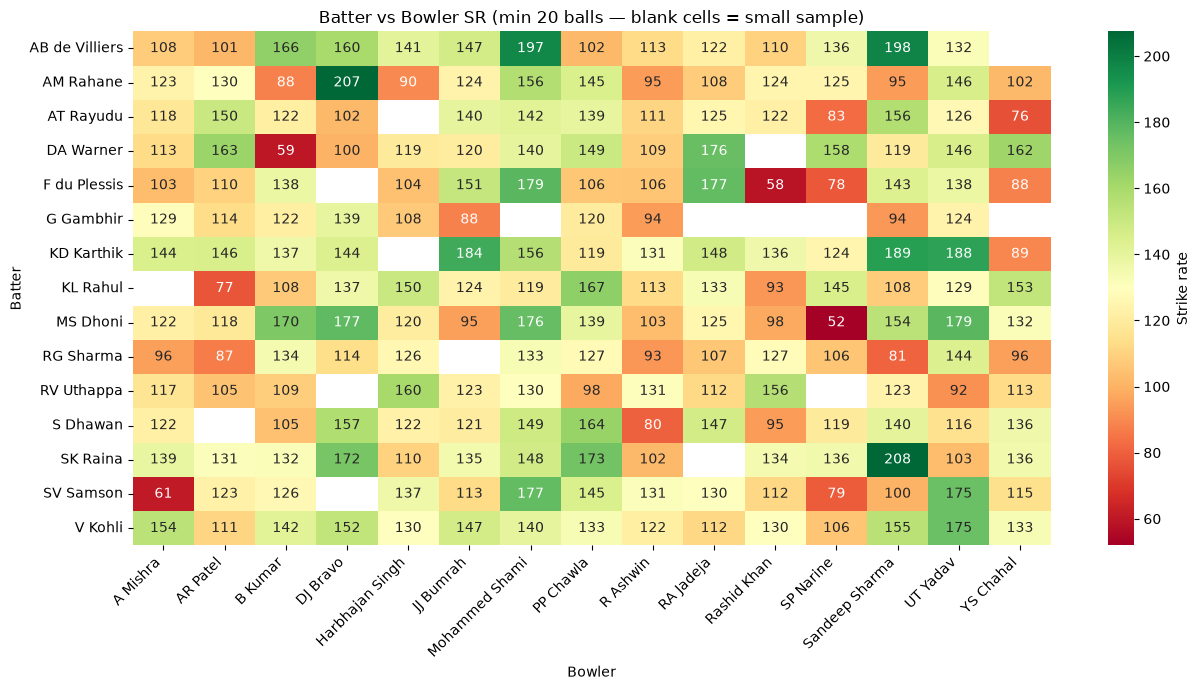

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

top_batters = (df.groupby("striker")["wides"].apply(lambda x: x.isna().sum())
               .nlargest(15).index.tolist())
top_bowlers = (df.groupby("bowler")["is_legal"].sum()
               .nlargest(15).index.tolist())

heat = (matchups_q[matchups_q["striker"].isin(top_batters)
                   & matchups_q["bowler"].isin(top_bowlers)]
        .pivot(index="striker", columns="bowler", values="SR"))

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdYlGn",
            center=130, cbar_kws={"label": "Strike rate"}, ax=ax)
ax.set_title("Batter vs Bowler SR (min 20 balls — blank cells = small sample)")
ax.set_xlabel("Bowler")
ax.set_ylabel("Batter")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [4]:
matchups_q.to_csv("../data/processed/matchups.csv", index=False)
print("Saved: data/processed/matchups.csv | shape:", matchups_q.shape)

Saved: data/processed/matchups.csv | shape: (3380, 8)
